# Inference Pipeline & Forecast Generation

End-to-end scoring pipeline loading the serialized 3-way ensemble (`final_spotter_ensemble.joblib`) to generate dollar rate predictions for `validation.csv` and the December lane forecast (`december-chart-inputs.csv`).

In [1]:
import numpy as np
import pandas as pd
import joblib
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / 'data').exists():
    ROOT = Path.cwd().parents[1]

In [ ]:
    
# Reusable End-to-End Prediction Function for Spotter's Validation / Submission File

def predict_spotter_rates(new_df, bundle_path="saved_models/final_spotter_ensemble.joblib"):
    """
    Takes a raw validation/submission DataFrame, applies identical cleaning,
    encoding, and feature transformations, and returns predicted dollar rates.
    """
    bundle = joblib.load(bundle_path)
    df = new_df.copy()
    
    # Fill any missing numeric values using training medians (never drop submission rows!)
    for col, med_val in bundle['train_medians'].items():
        if col in df.columns:
            df[col] = df[col].fillna(med_val)
            
    # Extract date features if raw 'date' column is present
    if 'date' in df.columns:
        dt = pd.to_datetime(df['date'])
        df['pickup_month'] = dt.dt.month
        df['pickup_day'] = dt.dt.day
        df = df.drop(columns=['date'])
        
    # One-hot encode categoricals (e.g., 'equipment')
    cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
    if cat_cols:
        df = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)
        
    # Build transformed feature matrices for Linear vs. Tree models
    X_lin, _  = transform_freight_data(df, model_type='linear', target_col='posted_rate')
    X_tree, _ = transform_freight_data(df, model_type='tree',   target_col='posted_rate')
    
    # Align exact column schemas from training
    X_lin  = X_lin.reindex(columns=bundle['linear_columns'], fill_value=0)
    X_tree = X_tree.reindex(columns=bundle['tree_columns'],   fill_value=0)
    
    # Predict in log-space, blend, and convert back to dollars
    w = bundle['weights']
    pred_log = (
        w['enet'] * bundle['models']['enet'].predict(X_lin) +
        w['lgbm'] * bundle['models']['lgbm'].predict(X_tree) +
        w['xgb']  * bundle['models']['xgb'].predict(X_tree)
    )
    
    return np.expm1(pred_log)

### Reusable Inference Function (`predict_spotter_rates`)
* **Zero-Row-Drop Imputation:** Fills missing numeric values using saved training medians rather than dropping rows.
* **Schema Alignment:** Re-extracts `pickup_month` and `pickup_day` (without `dayofweek`), applies one-hot encoding, runs `transform_freight_data` separately for linear and tree feature sets, and reindexes columns to match training schemas.
* **Log-Space Blending:** Computes the weighted ensemble average in log-space and converts back to USD via `np.expm1`.

In [3]:
import numpy as np
import pandas as pd

def haversine_miles(lat1, lon1, lat2, lon2):
    """Calculates great-circle distance in miles between two lat/lon points."""
    R = 3958.8
    phi1, phi2 = np.radians(lat1), np.radians(lat2)
    dphi = np.radians(lat2 - lat1)
    dlambda = np.radians(lon2 - lon1)
    a = np.sin(dphi / 2.0)**2 + np.cos(phi1) * np.cos(phi2) * np.sin(dlambda / 2.0)**2
    return 2 * R * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

def transform_freight_data(df, model_type='linear', target_col='posted_rate'):
    """
    Applies feature transformations independently to train or test splits.
    Assumes date extraction and categorical encoding are already completed.
    
    Parameters:
    - df: Pre-split and pre-encoded DataFrame (train or test)
    - model_type: 'linear' (drops raw distance to prevent VIF > 50) or 'tree' (keeps both)
    - target_col: Name of target column (if present, separates and log1p-transforms it)
    
    Returns:
    - X: Transformed feature DataFrame
    - y_log: Log1p-transformed target Series (or None if target_col not in df)
    """
    X = df.copy()
    
    # 1. Separate & log-transform target if present (invert predictions via np.expm1)
    y_log = None
    if target_col in X.columns:
        y_log = np.log1p(X[target_col])
        X = X.drop(columns=[target_col])
        
    # 2. Power-law distance transformation (R2 = 0.9364)
    if 'distance' in X.columns:
        X['log_distance'] = np.log1p(X['distance'])
        
    # 3. Spatial geometry features from coordinates (if present)
    coord_cols = {'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon'}
    if coord_cols.issubset(X.columns):
        hav_dist = haversine_miles(
            X['pickup_lat'], X['pickup_lon'],
            X['delivery_lat'], X['delivery_lon']
        )
        if 'distance' in X.columns:
            X['detour_ratio'] = X['distance'] / np.maximum(hav_dist, 1.0)
        X['delta_lat'] = X['delivery_lat'] - X['pickup_lat']
        X['delta_lon'] = X['delivery_lon'] - X['pickup_lon']
        
    # 4. Drop raw 'distance' for linear models to eliminate multicollinearity (VIF = 55.42)
    if model_type == 'linear' and 'distance' in X.columns:
        X = X.drop(columns=['distance'])
        
    # 5. Drop leaky column if still present
    if 'rate_per_mile' in X.columns:
        X = X.drop(columns=['rate_per_mile'])
        
    return X, y_log


### Validation Set Predictions (`validation.csv`)
Generate predictions for all 12,000 validation loads, verify zero missing predictions after merging on `load_id`, and export `data/validation_predictions.csv`.

In [4]:
val_data = pd.read_csv(ROOT / 'data/validation.csv')
val_pred = pd.read_csv(ROOT / 'data/validation-predictions-template.csv')
val_data['predicted_rate'] = predict_spotter_rates(val_data)

In [5]:
val_pred = val_pred.drop(columns=['predicted_rate'])
val_pred = val_pred.merge(val_data[['load_id', 'predicted_rate']], on='load_id', how='left')

In [6]:
val_pred['predicted_rate'].isnull().sum()  # Should be 0 if all load_ids matched correctly

np.int64(0)

In [7]:
val_pred.to_csv(ROOT / 'data/validation_predictions.csv', index=False)

### December Lane Forecast (`december-chart-inputs.csv`)
Enrich the December forecast inputs (`Lexington → Fort Wayne`, Dry Van, 360 mi, 32,000 lbs) with median origin/destination coordinates and lane-level `market_index` and `quote_signal` lookups from `train-test.csv` (with global training medians as fallback for unseen lanes), then generate daily rate forecasts across December 1–31, 2025.

In [8]:
import pandas as pd
import numpy as np
import joblib

# 1. Load your assessment forecast CSV directly
input_csv_path = "data/december-chart-inputs.csv"  # <-- Update with your actual CSV filename
forecast_df = pd.read_csv(ROOT/input_csv_path)
tt_df = pd.read_csv(ROOT / 'data/train-test.csv')  # Load your original training data for lookups

# 2. Dynamically build lookup tables from your original dataframe (tt_df)
pickup_lookup = (
    tt_df.groupby('pickup', as_index=False)[['pickup_lat', 'pickup_lon']]
    .median()
)
delivery_lookup = (
    tt_df.groupby('delivery', as_index=False)[['delivery_lat', 'delivery_lon']]
    .median()
)
lane_signals = (
    tt_df.groupby(['pickup', 'delivery'], as_index=False)[['market_index', 'quote_signal']]
    .median()
)

# 3. Dynamically merge coordinates and lane-level market signals onto forecast_df
enriched_df = (
    forecast_df
    .merge(pickup_lookup, on='pickup', how='left')
    .merge(delivery_lookup, on='delivery', how='left')
    .merge(lane_signals, on=['pickup', 'delivery'], how='left')
)

# Fallback to global training medians for any unseen cities/lanes (no hardcoded numbers)
for col in ['pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'market_index', 'quote_signal']:
    if col in enriched_df.columns:
        enriched_df[col] = enriched_df[col].fillna(tt_df[col].median())

# Drop text city columns and empty target column before inference
model_input_df = enriched_df.drop(columns=['pickup', 'delivery', 'predicted_rate'], errors='ignore')

# 4. Generate predictions using your saved 3-Way Ensemble
forecast_df['predicted_rate'] = np.round(
    predict_spotter_rates(model_input_df, bundle_path="saved_models/final_spotter_ensemble.joblib"),
    2
)

# 5. Save and inspect results
output_csv_path = "data/december-chart-inputs.csv"
forecast_df.to_csv(ROOT/output_csv_path, index=False)

print(f"Successfully generated {len(forecast_df)} predictions -> {output_csv_path}")
print(forecast_df.head(10).to_string(index=False))


Successfully generated 31 predictions -> data/december-chart-inputs.csv
   pickup   delivery  distance equipment  weight       date  predicted_rate
Lexington Fort Wayne       360   Dry Van   32000 2025-12-01          828.63
Lexington Fort Wayne       360   Dry Van   32000 2025-12-02          828.78
Lexington Fort Wayne       360   Dry Van   32000 2025-12-03          828.58
Lexington Fort Wayne       360   Dry Van   32000 2025-12-04          828.73
Lexington Fort Wayne       360   Dry Van   32000 2025-12-05          828.88
Lexington Fort Wayne       360   Dry Van   32000 2025-12-06          829.32
Lexington Fort Wayne       360   Dry Van   32000 2025-12-07          829.99
Lexington Fort Wayne       360   Dry Van   32000 2025-12-08          832.61
Lexington Fort Wayne       360   Dry Van   32000 2025-12-09          833.90
Lexington Fort Wayne       360   Dry Van   32000 2025-12-10          834.11


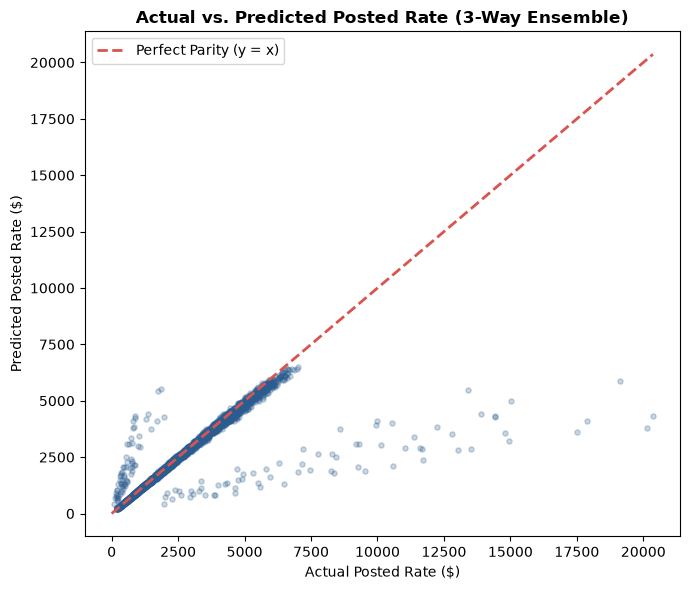

In [9]:
import matplotlib.pyplot as plt
import pandas as pd

test_raw = pd.read_csv(ROOT / "data/cleaned_raw_test.csv")
y_true = test_raw["posted_rate"]
y_pred = predict_spotter_rates(test_raw.drop(columns=["posted_rate"]))

plt.figure(figsize=(7, 6))
plt.scatter(y_true, y_pred, alpha=0.25, s=14, color="#2b5c8f")
max_val = max(y_true.max(), y_pred.max())
plt.plot([0, max_val], [0, max_val], "--", color="#d9534f", linewidth=2, label="Perfect Parity (y = x)")
plt.title("Actual vs. Predicted Posted Rate (3-Way Ensemble)", fontweight="bold")
plt.xlabel("Actual Posted Rate ($)")
plt.ylabel("Predicted Posted Rate ($)")
plt.legend()
plt.tight_layout()
plt.savefig(ROOT / "images/03_actual_vs_predicted.png", dpi=300, bbox_inches="tight")
plt.show()